In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/Himanshu-1703/reddit-sentiment-analysis/refs/heads/main/data/reddit.csv')

In [3]:
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [4]:
df.shape

(37249, 2)

In [5]:
df['category'].value_counts()

category
 1    15830
 0    13142
-1     8277
Name: count, dtype: int64

In [6]:
df.sample()['clean_comment'].values

<StringArray>
['inb4 history keeps changing ruling parties change ']
Length: 1, dtype: str

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37249 entries, 0 to 37248
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   clean_comment  37149 non-null  str  
 1   category       37249 non-null  int64
dtypes: int64(1), str(1)
memory usage: 582.1 KB


In [8]:
df.isnull().sum()

clean_comment    100
category           0
dtype: int64

In [9]:
df[df['clean_comment'].isnull()]

,clean_comment,category
413,NaN,0
605,NaN,0
2422,NaN,0
2877,NaN,0
3307,NaN,0
...,...,...
35975,NaN,0
36036,NaN,0
37043,NaN,0
37111,NaN,0


In [10]:
df.dropna(inplace = True)

C:\Users\win11\AppData\Local\Temp\ipykernel_24876\1791587065.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace = True)


In [11]:
df.duplicated().sum()

np.int64(350)

In [12]:
df[df.duplicated()]

,clean_comment,category
375,,0
392,,0
617,aurum mom,0
651,,0
1222,,0
...,...,...
36915,who won,0
37044,,0
37125,hari,0
37158,top kek,1


In [13]:
df.drop_duplicates(inplace=True)

C:\Users\win11\AppData\Local\Temp\ipykernel_24876\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [14]:
df = df[~(df['clean_comment'].str.strip() == '')]

In [15]:
df['clean_comment'] = df['clean_comment'].str.lower()

In [16]:
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [17]:
df[df['clean_comment'].apply(lambda x: x.endswith(' ') or x.startswith(' '))]

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1
...,...,...
37241,let the janta decide not ulema clerics,0
37242,hona hai same with vaccination education insu...,0
37246,downvote karna tha par upvote hogaya,0
37247,haha nice,1


In [18]:
df['clean_comment'] = df['clean_comment'].str.strip()

In [19]:
df.head()

,clean_comment,category
0,family mormon have never tried explain them th...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [20]:
df['clean_comment'].apply(lambda x: x.endswith(' ') or x.startswith(' ')).sum()

np.int64(0)

In [21]:
url_pattern = r'https?://[^\s]+'
comments_with_urls = df[df['clean_comment'].str.contains(url_pattern,regex=True)]
comments_with_urls.head()


,clean_comment,category


In [22]:
comments_with_newline = df[df['clean_comment'].str.contains('\n')]
comments_with_newline.head()

,clean_comment,category
448,what missing jpg\nand why this brilliant edit ...,1
781,india has been ruined congress and populist sc...,-1
847,like aap for its stand corruption and making p...,-1
871,reduced trade\ndeficit stronger rupee aren the...,0
1354,amsa press conference australian maritime safe...,1


In [23]:
df.loc[448]

clean_comment    what missing jpg\nand why this brilliant edit ...
category                                                         1
Name: 448, dtype: object

In [24]:
df['clean_comment'] = df['clean_comment'].str.replace('\n',' ',regex=True)

In [25]:
comments_with_newline = df[df['clean_comment'].str.contains('\n')]
comments_with_newline.head()

,clean_comment,category


## EDA initial

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='category', ylabel='count'>

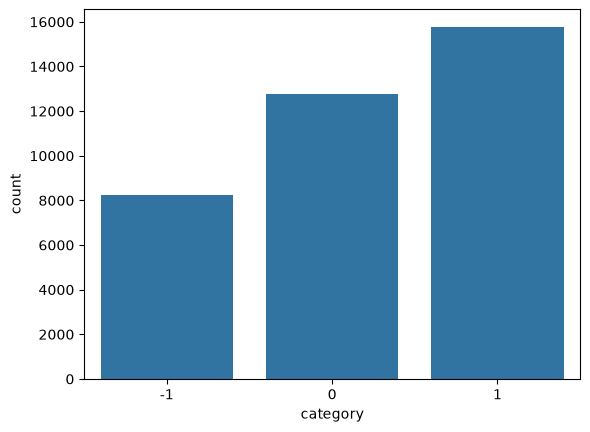

In [27]:
sns.countplot(data = df,x = 'category')

In [28]:
df['category'].value_counts(normalize=True)

category
 1    0.428641
 0    0.347131
-1    0.224227
Name: proportion, dtype: float64

In [29]:
df['word_count'] = df['clean_comment'].apply(lambda x:len(x.split()))

In [30]:
df.head()

,clean_comment,category,word_count
0,family mormon have never tried explain them th...,1,39
1,buddhism has very much lot compatible with chr...,1,196
2,seriously don say thing first all they won get...,-1,86
3,what you have learned yours and only yours wha...,0,29
4,for your own benefit you may want read living ...,1,112


In [31]:
df['word_count'].describe()

count    36793.000000
mean        29.667464
std         56.790738
min          1.000000
25%          6.000000
50%         13.000000
75%         30.000000
max       1307.000000
Name: word_count, dtype: float64

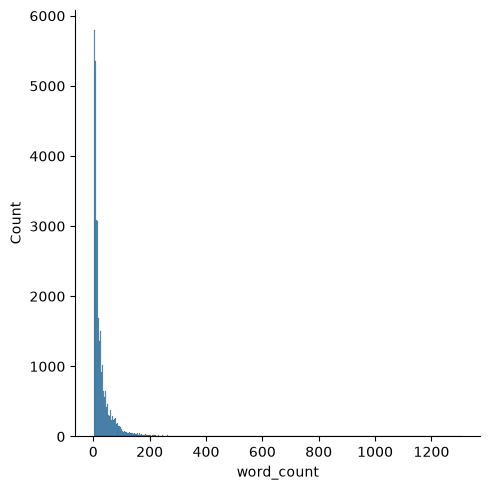

In [32]:
sns.displot(data=df,x = 'word_count')

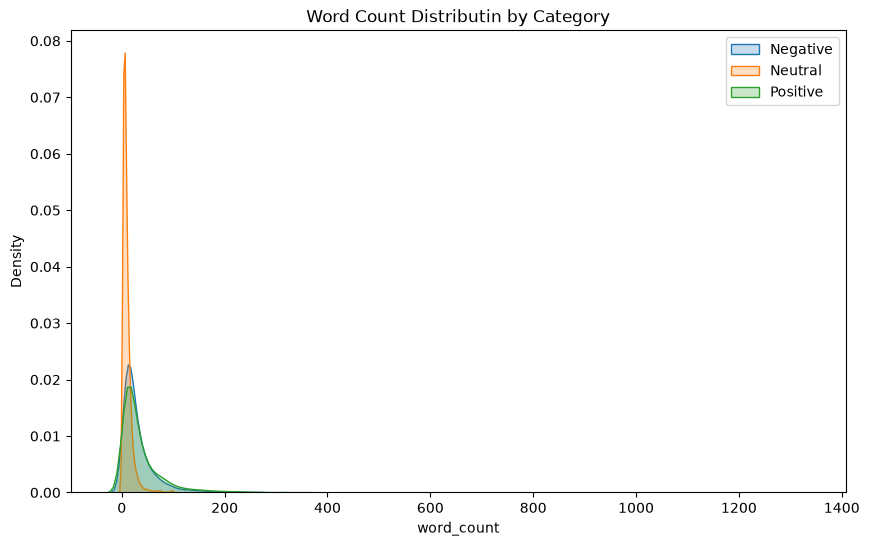

In [33]:
plt.figure(figsize=(10,6))

sns.kdeplot(data=df[df['category'] == -1], x = 'word_count', label ='Negative',fill = True)
sns.kdeplot(data=df[df['category'] == 0], x = 'word_count', label ='Neutral',fill = True)
sns.kdeplot(data=df[df['category'] == 1], x = 'word_count', label ='Positive',fill = True)

plt.title('Word Count Distributin by Category')
plt.legend()

<Axes: ylabel='word_count'>

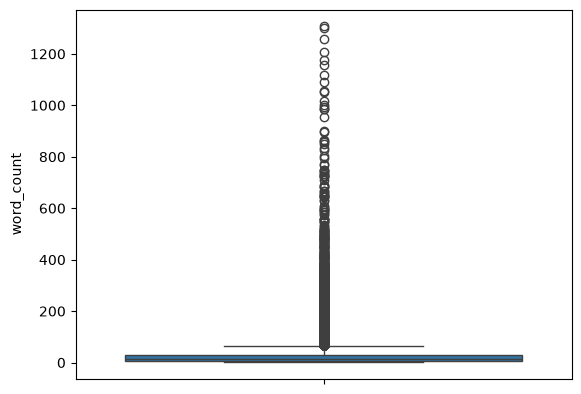

In [34]:
sns.boxplot(df['word_count'])

<Axes: xlabel='category', ylabel='word_count'>

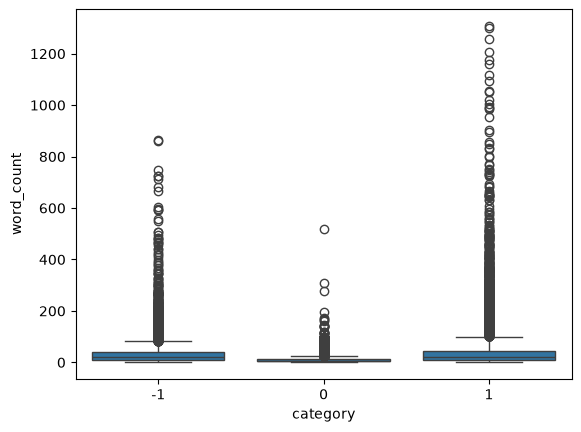

In [35]:
plt.Figure(figsize = (10,6))

sns.boxplot(data=df, x = 'category', y = 'word_count')

<Axes: xlabel='category', ylabel='word_count'>

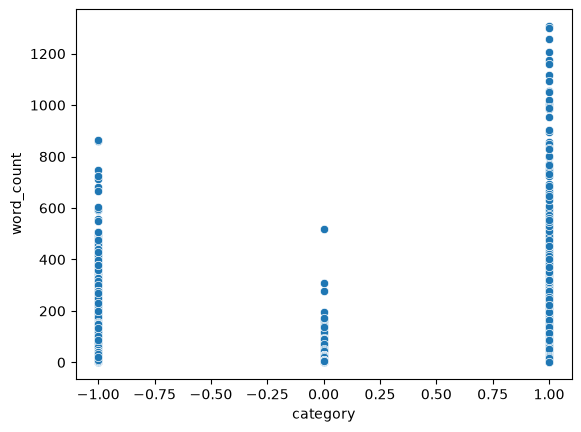

In [36]:
sns.scatterplot(data=df, x = 'category', y= 'word_count')

<Axes: xlabel='category', ylabel='word_count'>

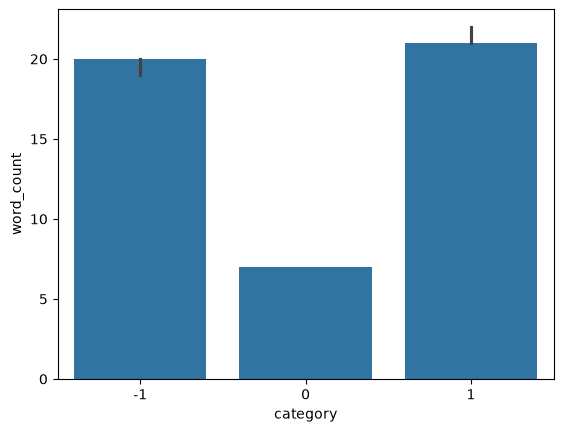

In [37]:
sns.barplot(data = df , x = 'category', y = 'word_count', estimator='median')

In [38]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words= set(stopwords.words('english'))
df['num_stop_words'] = df['clean_comment'].apply(lambda x: len([word for word in x.split() if word in stop_words]))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\win11\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [39]:
df.head()

,clean_comment,category,word_count,num_stop_words
0,family mormon have never tried explain them th...,1,39,13
1,buddhism has very much lot compatible with chr...,1,196,59
2,seriously don say thing first all they won get...,-1,86,40
3,what you have learned yours and only yours wha...,0,29,15
4,for your own benefit you may want read living ...,1,112,45


<Axes: xlabel='category', ylabel='num_stop_words'>

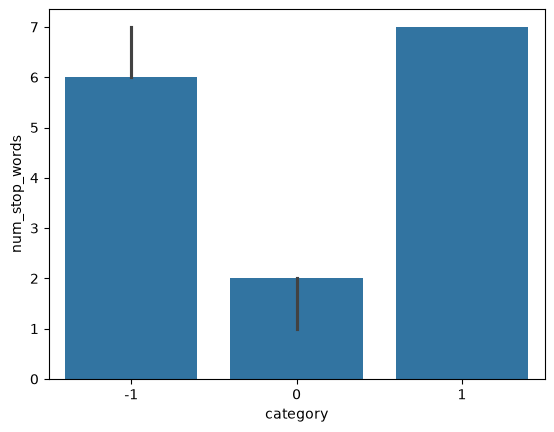

In [40]:
sns.barplot(data=df, x = 'category',y = 'num_stop_words', estimator='median')

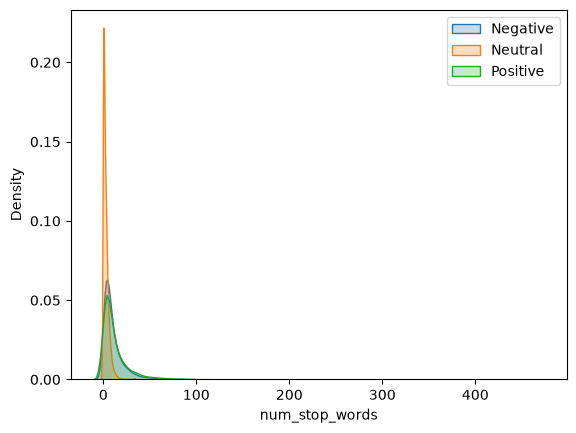

In [41]:
plt.Figure(figsize=(10,6))
sns.kdeplot( df[df['category'] == -1]['num_stop_words'],label = 'Negative',fill = True )
sns.kdeplot( df[df['category'] == 0]['num_stop_words'],label = 'Neutral',fill = True )
sns.kdeplot( df[df['category'] == 1]['num_stop_words'],label = 'Positive',fill = True )
plt.legend()

C:\Users\win11\AppData\Local\Temp\ipykernel_24876\1878164778.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = top_25_df, x = 'count', y= 'stop_words', palette='viridis')


<Axes: xlabel='count', ylabel='stop_words'>

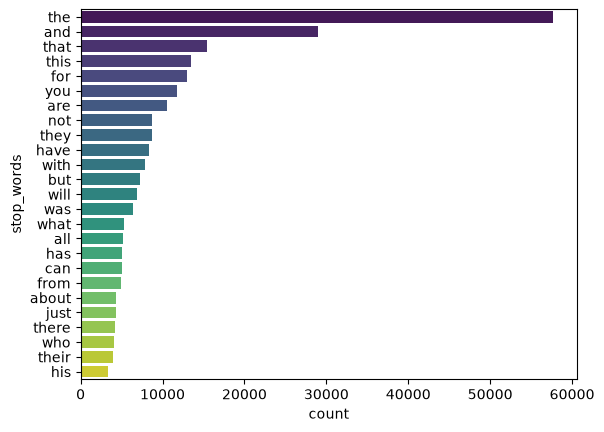

In [42]:
from collections import Counter
all_stop_words = [word for comment in df['clean_comment'] for word in comment.split() if word in stop_words]
most_common_stop_words = Counter(all_stop_words).most_common(25)
top_25_df = pd.DataFrame(most_common_stop_words, columns = ['stop_words', 'count'])

plt.Figure(figsize=(10,6))
sns.barplot(data = top_25_df, x = 'count', y= 'stop_words', palette='viridis')

In [43]:
df['num_char'] = df['clean_comment'].apply(len)

In [44]:
df.head()

,clean_comment,category,word_count,num_stop_words,num_char
0,family mormon have never tried explain them th...,1,39,13,259
1,buddhism has very much lot compatible with chr...,1,196,59,1268
2,seriously don say thing first all they won get...,-1,86,40,459
3,what you have learned yours and only yours wha...,0,29,15,167
4,for your own benefit you may want read living ...,1,112,45,690


In [45]:
df['num_char'].describe()

count    36793.000000
mean       181.852798
std        359.702163
min          1.000000
25%         38.000000
50%         80.000000
75%        184.000000
max       8664.000000
Name: num_char, dtype: float64

In [46]:
from collections import Counter 
all_text = ' '.join(df['clean_comment'])
char_frequency = Counter(all_text)

char_frequency_df = pd.DataFrame(char_frequency.items(), columns=['character','frequency']).sort_values(by='frequency',ascending=False)

In [47]:
char_frequency_df

,character,frequency
6,,1091592
12,e,666610
13,t,491287
1,a,481134
3,i,401388
...,...,...
1345,唯,1
1346,统,1
1330,段,1
1331,她,1


In [48]:
df['num_punctuation_chars'] = df['clean_comment'].apply(lambda x: sum([1 for char in x if char in '.,!?;:"\'()[]{}-']))
df.sample(5)

,clean_comment,category,word_count,num_stop_words,num_char,num_punctuation_chars
11033,•people have right know where our funds are co...,1,28,9,166,0
12597,very very good signs for modi the key retainin...,1,39,16,217,0
15433,new meetup thread,1,3,0,17,0
1958,martins thought pappa was going run they even ...,0,12,2,73,0
22976,just one man and his cabal running the country...,1,68,29,383,0


In [49]:
df['num_punctuation_chars'].value_counts()

num_punctuation_chars
0    36793
Name: count, dtype: int64

C:\Users\win11\AppData\Local\Temp\ipykernel_24876\380934205.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = top_25_bigrams_df, x = 'count', y = 'bigram', palette='magma')


<Axes: xlabel='count', ylabel='bigram'>

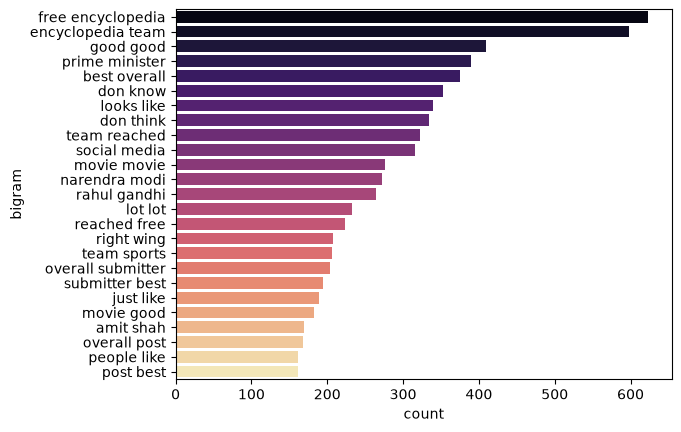

In [51]:
from sklearn.feature_extraction.text import CountVectorizer

def get_top_ngrams(corpus, n= None):
    vec = CountVectorizer(ngram_range=(2,2), stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis = 0)
    words_freq = [(word, sum_words[0,idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq,key = lambda x: x[1], reverse=True)
    return words_freq[:n]

top_25_bigrams = get_top_ngrams(df['clean_comment'], 25)

top_25_bigrams_df = pd.DataFrame(top_25_bigrams, columns = ['bigram','count'])

plt.Figure(figsize=(10,6))
sns.barplot(data = top_25_bigrams_df, x = 'count', y = 'bigram', palette='magma')


C:\Users\win11\AppData\Local\Temp\ipykernel_24876\4206464434.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = top_25_trigrams_df, x = 'count', y = 'trigram', palette='magma')


<Axes: xlabel='count', ylabel='trigram'>

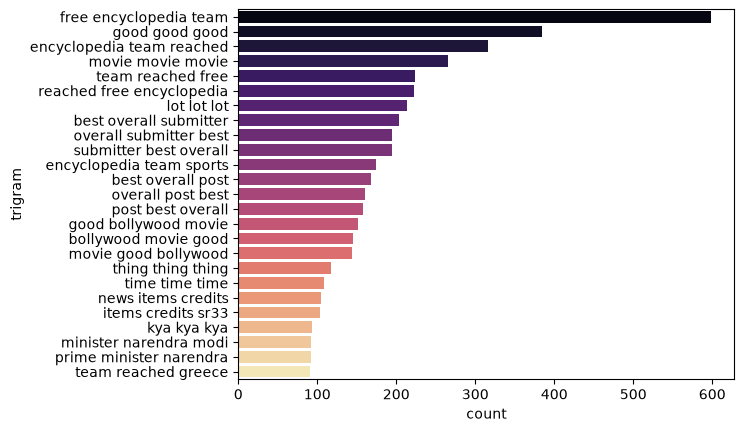

In [52]:
def get_top_ngrams(corpus, n= None):
    vec = CountVectorizer(ngram_range=(3,3), stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis = 0)
    words_freq = [(word, sum_words[0,idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq,key = lambda x: x[1], reverse=True)
    return words_freq[:n]

top_25_trigrams = get_top_ngrams(df['clean_comment'], 25)

top_25_trigrams_df = pd.DataFrame(top_25_trigrams, columns = ['trigram','count'])

plt.Figure(figsize=(10,6))
sns.barplot(data = top_25_trigrams_df, x = 'count', y = 'trigram', palette='magma')

In [53]:
import re
df['clean_comment'] = df['clean_comment'].apply(lambda x: re.sub(r'[^A-Za-z0-9\s!?.,]','',str(x)))

In [54]:
all_text = ' '.join(df['clean_comment'])

char_frequency = Counter(all_text)
char_frequency_df = pd.DataFrame(char_frequency.items(), columns=['character','frequency']).sort_values(by= 'frequency', ascending=False)

In [55]:
char_frequency_df

,character,frequency
6,,1091592
12,e,666610
13,t,491287
1,a,481134
3,i,401388
9,n,388465
7,o,379908
17,s,355279
8,r,331425
10,h,296748


In [56]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english')) - {'not', 'but', 'however', 'no', 'yet'}

df['clean_comment'] = df['clean_comment'].apply(lambda x: ' '.join([word for word in x.split() if word.lower() not in stop_words]))

In [57]:
df.head()

,clean_comment,category,word_count,num_stop_words,num_char,num_punctuation_chars
0,family mormon never tried explain still stare ...,1,39,13,259,0
1,buddhism much lot compatible christianity espe...,1,196,59,1268,0
2,seriously say thing first get complex explain ...,-1,86,40,459,0
3,learned want teach different focus goal not wr...,0,29,15,167,0
4,benefit may want read living buddha living chr...,1,112,45,690,0


In [58]:
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')
lemitizer = WordNetLemmatizer()

df['clean_comment'] = df['clean_comment'].apply(lambda x: ' '.join([lemitizer.lemmatize(word) for word in x.split()]))

df.head()

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\win11\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


,clean_comment,category,word_count,num_stop_words,num_char,num_punctuation_chars
0,family mormon never tried explain still stare ...,1,39,13,259,0
1,buddhism much lot compatible christianity espe...,1,196,59,1268,0
2,seriously say thing first get complex explain ...,-1,86,40,459,0
3,learned want teach different focus goal not wr...,0,29,15,167,0
4,benefit may want read living buddha living chr...,1,112,45,690,0


In [60]:
from wordcloud import WordCloud

def plot_word_cloud(text):
    wordcloud = WordCloud(width= 800, height= 400, background_color='white').generate(' '.join(text))
    plt.figure(figsize=(10,5))
    plt.imshow(wordcloud, interpolation= 'bilinear')
    plt.axis('off')
    plt.show()

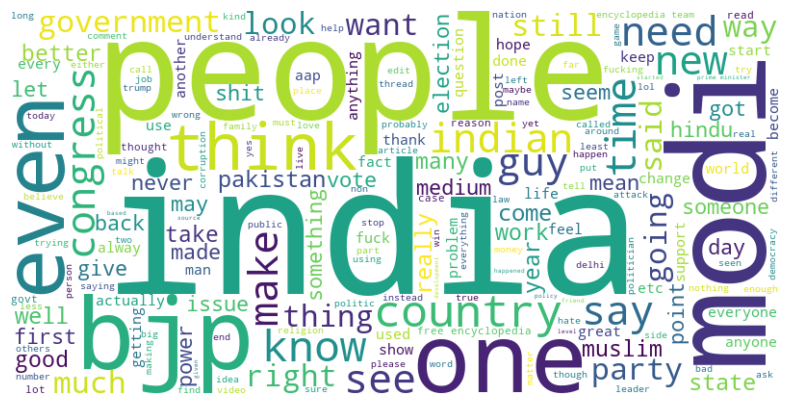

In [61]:
plot_word_cloud(df['clean_comment'])

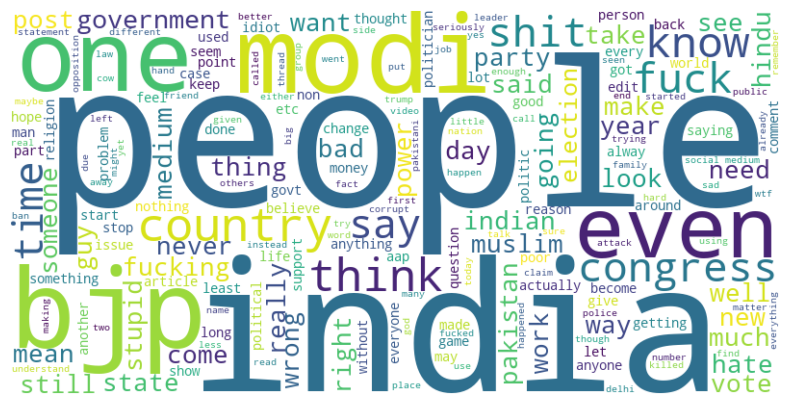

In [62]:
plot_word_cloud(df[df['category'] == -1]['clean_comment'])

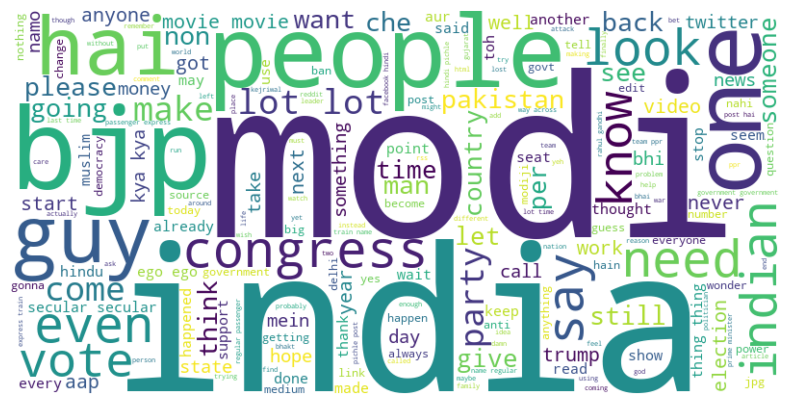

In [63]:
plot_word_cloud(df[df['category'] == 0]['clean_comment'])

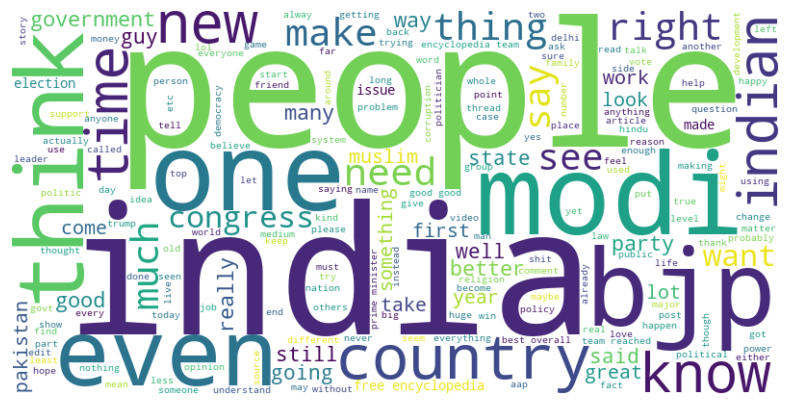

In [64]:
plot_word_cloud(df[df['category'] == 1]['clean_comment'])